In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

from tqdm import tqdm

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath} \usepackage{xfrac}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 11,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'marker': 'o',
                  'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

def set_size(width="revtex4.2", fraction=1, subplots=(1, 1), golden_ratio = 0.6180339887498949):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'revtex4.2':
        width_pt = 510.0
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

def load_training_results(file_name: str, data_folder = "../data/optimisation_data/"):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(data_folder + file_name, 'r') as file:
        res = json.load(file)

        # Params during training
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]

        # Params of the MPOs, self-explanatory
        mpo_params_keys = [] #['params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo']
        for key in mpo_params_keys:
            res[key] = {int(k): np.real_if_close(np.array(v, dtype=complex)) for k, v in res[key].items()}
        
        ignore_keys = ['probs', 'data_file', 'params', 'noise_type', 'lr'] + mpo_params_keys
        for k in set(res.keys()).difference(ignore_keys):
            res[k] = np.real_if_close(np.array(res[k], dtype=complex))
        
    return res

In [2]:
global_strategy = {'1e6': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed13.json',
                           'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed14.json',
                           'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed15.json']}

local1 = {'1e6': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000008_local1_sic_states_2023-12-11_seed660101.json',
                  'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000008_local1_sic_states_2023-12-11_seed660102.json',
                  'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000008_local1_sic_states_2023-12-11_seed660103.json']}

local2 = {'1e6': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000080_local2_sic_states_2023-12-11_seed660201.json',
                  'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000080_local2_sic_states_2023-12-11_seed660202.json',
                  'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000080_local2_sic_states_2023-12-11_seed660203.json']}

local3 = {'1e6': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000512_local3_sic_states_2023-12-11_seed660301.json',
                  'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000512_local3_sic_states_2023-12-11_seed660302.json',
                  'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000512_local3_sic_states_2023-12-11_seed660303.json']}

In [3]:
metrics_keys = ['frob_distance', 'test_loss', 'lpdo_trace']

noise_models = {'l1': local1, 'l2': local2, 'l3': local3, 'global': global_strategy}

processed_data = {}
for noise_type, noise_data in noise_models.items():  
    print(f"\nProcessing {noise_type}:")         
    
    best_frob_dists = {k: [] for k in noise_data.keys()}
    for shots, files in noise_data.items():
        
        tmp_dict = {k: [] for k in metrics_keys}
        for f in files:
            print(f" > Loading and processing file: {f}")
            data = load_training_results(f)
            [tmp_dict[k].append(data[k]) for k in tmp_dict.keys()]

        idx_min_loss = [np.argmin(yy) for yy in tmp_dict['test_loss']]
        best_vals = np.array([dist[idx] for dist, idx in zip(tmp_dict['frob_distance'], idx_min_loss)])
        print(best_vals)
        best_vals = np.sort(best_vals)[:3] # pick only the best three values
        best_frob_dists[shots] = np.mean(best_vals), np.std(best_vals)
        print(best_vals)

    processed_data[noise_type] = best_frob_dists

processed_data


Processing l1:
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000008_local1_sic_states_2023-12-11_seed660101.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000008_local1_sic_states_2023-12-11_seed660102.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000008_local1_sic_states_2023-12-11_seed660103.json
[0.54049671 0.74152969 0.73176193]
[0.54049671 0.73176193 0.74152969]

Processing l2:
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000080_local2_sic_states_2023-12-11_seed660201.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000080_local2_sic_states_2023-12-11_seed660202.json
 > Loading and processing file: cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000080_local2_sic_states_2023-12-11_seed660203.json
[0.01017634 0.01004487 0.0100724 ]
[0.01004487 0.0100724  0.01017634]

Processing l3:
 > Loading and processing file: cxeven_nq10_

{'l1': {'1e6': (0.6712627758511945, 0.09255151819366042)},
 'l2': {'1e6': (0.01009786890967701, 5.661559073580918e-05)},
 'l3': {'1e6': (7.262348482413768e-05, 2.9038055880438168e-05)},
 'global': {'1e6': (4.9291838731998126e-05, 2.8806340542332763e-06)}}

0 l1
1 l2
2 l3
3 global


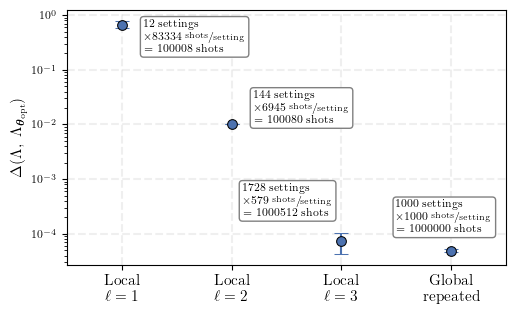

In [6]:
markersize = 7
capsize = 5

fig = plt.figure(figsize=set_size(fraction=0.75))

# Noise with error-bars
for i, (k, vals_dicts) in enumerate(processed_data.items()):
    print(i, k)
    for v in vals_dicts.values():
        plt.errorbar(i, v[0], yerr = v[1], color = cmap[0], marker = 'o',  markersize = markersize, capsize = capsize, markeredgecolor='black', capthick=1, mew=0.75)
    #plt.errorbar([], [], color = color, marker = marker, markersize = markersize, capsize = capsize, markeredgecolor='black', label=label, mew=0.75)

style_kwargs = {'ha': "left", 'va': "center", 'fontsize': 8, 'bbox': {'boxstyle':"round,pad=0.3", 'fc':"w", 'ec':"grey", 'lw':1}}
plt.annotate("12 settings\n"   + r"$\times 83334~\sfrac{\text{shots}}{\text{setting}}$" + "\n = 100008 shots", (0.2, 4e-1), **style_kwargs)
plt.annotate("144 settings\n"  + r"$\times 6945~\sfrac{\text{shots}}{\text{setting}}$"  + "\n = 100080 shots", (1.2, 2e-2), **style_kwargs)
plt.annotate("1728 settings\n" + r"$\times 579~\sfrac{\text{shots}}{\text{setting}}$"   + "\n = 1000512 shots", (1.1, 4e-4),**style_kwargs)
plt.annotate("1000 settings\n" + r"$\times 1000~\sfrac{\text{shots}}{\text{setting}}$"  + "\n = 1000000 shots", (2.5, 2e-4), **style_kwargs)

plt.yscale('log')

plt.xlim([-0.5,3.5])
plt.xticks([0,1,2,3], labels = ['Local \n $\ell=1$', 'Local \n $\ell=2$', 'Local \n $\ell = 3$', 'Global \n repeated'], fontsize=11)

plt.ylabel(r"$\Delta(\Lambda,~\Lambda_{\boldsymbol{\theta_\textrm{opt}}})$")

plt.grid(ls = "--", lw = 1.5, alpha = 0.2)

plt.tight_layout()
plt.savefig('delta_locality_vs_golbality.pdf', format="pdf")

In [ ]:
1728 * 579

In [ ]:
for shots in shots_keys:
    for metric in metrics_keys:
        data_per_shots[shots][metric] = np.real_if_close(np.array(data_per_shots[shots][metric]), tol=1e-12)    
        
        x = data_per_shots[shots][metric]

        min_loss = np.min(xx) 

        ###########################
        # Check dimensions of data (if different prolongate shorter with same value to compute values)
        ###########################
        training_epochs = [len(xx) for xx in x]
        
        # If optimisation finished at different epochs
        if not np.all(np.isclose(training_epochs, training_epochs[0])):
            e_max = max(training_epochs)
            x_new = np.zeros((len(x), e_max))
            for i, xx in enumerate(x):
                xx = np.hstack([xx, [xx[-1]] * (e_max - len(xx))]) # Homogenise data to the longest training run
                x_new[i] = xx
            x = x_new
        ###########################

        # Mean and standard deviation
        mu, std = np.mean(x, axis=0), np.std(x, axis=0)

        data_per_shots[shots]['avg_' + metric] = mu
        data_per_shots[shots]['std_' + metric] = std

In [ ]:
plt.plot(data_per_shots['1e3']['avg_test_loss'])

In [ ]:
np.all(np.isclose(numbers, numbers[0]))

In [ ]:
averaged_data['1e3']['frob_distance'] = np.array(averaged_data['1e3']['frob_distance'])

In [ ]:
averaged_data['1e3']['frob_distance']